# Face recognition: benchmark (ROC, AUC, speed)

Data (see README): `data/gallery/<person>/*.jpg` (known people) and `data/strangers/*.jpg` (people NOT in the gallery).

**Two kinds of pairs are compared with cosine similarity:**
- *genuine* pair = two photos of the same person (should score high)
- *impostor* pair = two photos of different people, including gallery vs stranger (should score low)

The ROC curve shows how well a threshold separates the two groups.

In [1]:
!pip -q install deepface tf-keras


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, time, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from deepface import DeepFace
from sklearn.metrics import roc_curve, auc

ROOT = ".."   # project root when this notebook lives in notebooks/. On Kaggle, point it to your dataset folder.
GALLERY = f"{ROOT}/data/gallery"
STRANGERS = f"{ROOT}/data/strangers"
RESULTS = f"{ROOT}/results"
os.makedirs(RESULTS, exist_ok=True)

MODELS = ["Facenet512", "ArcFace", "VGG-Face"]
DETECTOR = "opencv"      # must match src/recognizer.py
TARGET_FAR = 0.01        # accepted rate of strangers wrongly recognized
EXT = (".jpg", ".jpeg", ".png")

26-10-06 15:15:26 - ⚠️ 
 ⚠️ DEPRECATION WARNING:
 Running 'pip install deepface' alone will no longer be sufficient and will
 NOT install a default backend in an upcoming major release.

 Currently, TensorFlow is included by default, but this behavior will be deprecated.
 Please explicitly specify your preferred backend engine when installing:

   -> pip install deepface[tensorflow]
   -> pip install deepface[pytorch]

 Otherwise, you will encounter 'module not found' errors.




In [3]:
gallery_items = [(p, os.path.join(GALLERY, p, f))
                 for p in sorted(os.listdir(GALLERY)) if os.path.isdir(os.path.join(GALLERY, p))
                 for f in sorted(os.listdir(os.path.join(GALLERY, p))) if f.lower().endswith(EXT)]
stranger_items = [("stranger", os.path.join(STRANGERS, f))
                  for f in sorted(os.listdir(STRANGERS)) if f.lower().endswith(EXT)]
print(len(gallery_items), "gallery photos,", len({p for p, _ in gallery_items}), "people;",
      len(stranger_items), "stranger photos")

12 gallery photos, 4 people; 7 stranger photos


## 1. Embeddings and speed

`embed` returns the normalized embeddings and the **average time per image** (face detection + embedding). One untimed call first, because the first call loads the model and would distort the measure.

In [4]:
import cv2
for _, p in gallery_items[:3]:
    img = cv2.imread(p)
    print(p, "-> could not read" if img is None else img.shape)

for det in ["opencv", "ssd", "mtcnn", "retinaface", "yunet", "mediapipe"]:
    ok, err = 0, ""
    for _, p in gallery_items:
        try:
            DeepFace.extract_faces(img_path=p, detector_backend=det, enforce_detection=True)
            ok += 1
        except Exception as e:
            err = str(e)[:80]
    print(f"{det:11s} {ok}/{len(gallery_items)} faces found   {err}")

../data/gallery\Hayao Miyazaki\images (1).jpg (445, 688, 3)
../data/gallery\Hayao Miyazaki\images (3).jpg (542, 565, 3)
../data/gallery\Hayao Miyazaki\images.jpg (530, 577, 3)
opencv      0/12 faces found   ('Confirm that opencv is installed on your environment! Expected path ', 'c:\\Us
ssd         0/12 faces found   Exception while calling opencv.dnn module.This is an optional dependency.You can
mtcnn       12/12 faces found   
retinaface  12/12 faces found   
yunet       12/12 faces found   
mediapipe   0/12 faces found   MediaPipe is an optional detector, ensure the library is installed. Please insta


In [5]:
DETECTOR = "yunet"          # <- set it right here
print("detector used:", DETECTOR)
def embed(model, items):
    try:   # warm-up (loads the model, not timed)
        DeepFace.represent(img_path=items[0][1], model_name=model,
                           detector_backend=DETECTOR, enforce_detection=False)
    except Exception:
        pass
    embs, labels, times = [], [], []
    for label, path in items:
        t = time.perf_counter()
        try:
            r = DeepFace.represent(img_path=path, model_name=model,
                                   detector_backend=DETECTOR, enforce_detection=True)[0]
        except ValueError:
            print("no face found:", path); continue
        times.append(time.perf_counter() - t)
        v = np.asarray(r["embedding"], dtype=np.float32)
        embs.append(v / np.linalg.norm(v)); labels.append(label)
    if not embs:
        raise ValueError(
            f"No face embeddings were generated from {len(items)} images for {model}. "
            f"Check the image paths/content or try a different detector backend "
            f"(current: {DETECTOR!r})."
        )
    return np.array(embs), np.array(labels), 1000 * float(np.mean(times))

data = {}
for m in MODELS:
    Eg, Lg, ms = embed(m, gallery_items)
    Es, _, _ = embed(m, stranger_items)
    data[m] = (Eg, Lg, Es, ms)
    print(f"{m}: dim={Eg.shape[1]}  {ms:.0f} ms/image")

detector used: yunet
Facenet512: dim=512  550 ms/image
26-10-06 15:22:21 - 🔗 arcface_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/arcface_weights.h5 to C:\Users\hp\.deepface\weights\arcface_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/arcface_weights.h5
To: C:\Users\hp\.deepface\weights\arcface_weights.h5
100%|██████████| 137M/137M [00:23<00:00, 5.87MB/s] 


ArcFace: dim=512  405 ms/image
26-10-06 15:22:56 - 🔗 vgg_face_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/vgg_face_weights.h5 to C:\Users\hp\.deepface\weights\vgg_face_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/vgg_face_weights.h5
To: C:\Users\hp\.deepface\weights\vgg_face_weights.h5
100%|██████████| 580M/580M [02:56<00:00, 3.28MB/s] 


VGG-Face: dim=4096  766 ms/image


## 2. Scores, ROC and metrics

Small dataset warning: with ~25 gallery photos you have only a few dozen genuine pairs and a few hundred impostor pairs. FAR can only be measured down to about 1/(number of impostor pairs), so we use FAR 10% and 1%, not 0.1%.

In [6]:
def pair_scores(Eg, Lg, Es):
    S = Eg @ Eg.T
    same = Lg[:, None] == Lg[None, :]
    iu = np.triu_indices(len(Eg), 1)
    s, y = S[iu], same[iu].astype(int)
    if len(Es):
        cross = (Es @ Eg.T).ravel()          # every stranger vs every gallery photo
        s = np.concatenate([s, cross]); y = np.concatenate([y, np.zeros(len(cross), int)])
    return s, y

def far_threshold(fpr, thr, far):
    j = max(np.searchsorted(fpr, far, side="right") - 1, 0)
    return j

def identification(Eg, Lg, Es, thr):
    """Rank-1 accuracy (leave-one-out) and stranger rejection, like the real app."""
    S = Eg @ Eg.T; np.fill_diagonal(S, -1)       # a photo must not match itself
    best = S.argmax(1); score = S.max(1)
    ok = np.array([Lg[b] == l for b, l in zip(best, Lg)])
    rank1 = ok.mean()
    correct_accept = (ok & (score >= thr)).mean()
    rejected = (( Es @ Eg.T).max(1) < thr).mean() if len(Es) else np.nan
    return rank1, correct_accept, rejected

rows, curves = [], {}
for m, (Eg, Lg, Es, ms) in data.items():
    s, y = pair_scores(Eg, Lg, Es)
    fpr, tpr, thr = roc_curve(y, s)
    fnr = 1 - tpr
    i = int(np.nanargmin(np.abs(fnr - fpr)))
    j = far_threshold(fpr, thr, TARGET_FAR)
    t = float(thr[j])
    rank1, corr, rej = identification(Eg, Lg, Es, t)
    rows.append({"model": m, "AUC": auc(fpr, tpr), "EER": (fpr[i] + fnr[i]) / 2,
                 "TAR@FAR=0.1": tpr[far_threshold(fpr, thr, 0.1)],
                 "TAR@FAR=0.01": tpr[j], "threshold": t,
                 "rank1_acc": rank1, "correct_accept": corr, "stranger_rejection": rej,
                 "ms_per_image": ms})
    curves[m] = (fpr, tpr)

table = pd.DataFrame(rows).set_index("model").round(3)
table.to_csv(f"{RESULTS}/metrics_table.csv")
table

,AUC,EER,TAR@FAR=0.1,TAR@FAR=0.01,threshold,rank1_acc,correct_accept,stranger_rejection,ms_per_image
model,,,,,,,,,
Facenet512,0.995,0.063,1.0,0.917,0.508,1.0,1.0,0.857,550.083
ArcFace,1.000,0.000,1.0,1.000,0.342,1.0,1.0,1.000,404.545
VGG-Face,0.998,0.004,1.0,1.000,0.343,1.0,1.0,1.000,766.007


### How to read the table
- **AUC / EER**: overall separation of genuine vs impostor (AUC near 1, EER near 0 is good).
- **TAR@FAR**: share of real matches kept while accepting only that share of wrong matches.
- **rank1_acc**: the closest gallery photo is the right person (ignores the threshold).
- **correct_accept**: right person AND score above the threshold (what the app really outputs).
- **stranger_rejection**: strangers correctly labelled "Unknown" at that threshold.
- **ms_per_image**: speed. Pick the model with the best trade-off, not only the best AUC.

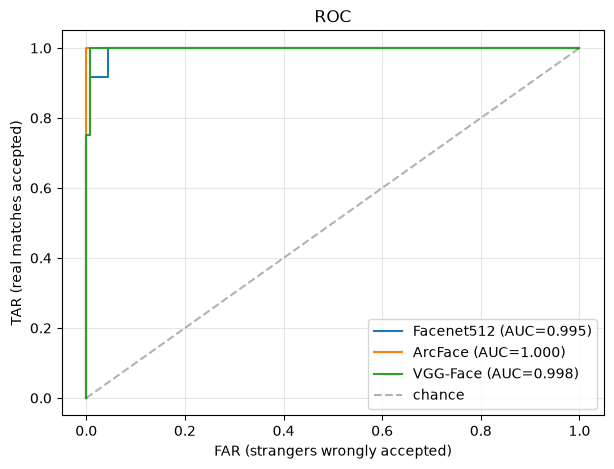

In [7]:
plt.figure(figsize=(7, 5))
for m, (fpr, tpr) in curves.items():
    plt.plot(fpr, tpr, label=f"{m} (AUC={table.loc[m, 'AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=.3, label="chance")
plt.xlabel("FAR (strangers wrongly accepted)"); plt.ylabel("TAR (real matches accepted)")
plt.title("ROC"); plt.grid(alpha=.3); plt.legend()
plt.savefig(f"{RESULTS}/roc_curve.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Choose the model and threshold for the app

In [8]:
best = table["TAR@FAR=0.01"].sort_values(ascending=False).index[0]
cfg = {"model": best, "detector": DETECTOR, "threshold": float(table.loc[best, "threshold"]),
       "target_far": TARGET_FAR, "ms_per_image": float(table.loc[best, "ms_per_image"])}
json.dump(cfg, open(f"{RESULTS}/threshold.json", "w"), indent=2)
print(cfg)

{'model': 'ArcFace', 'detector': 'yunet', 'threshold': 0.342, 'target_far': 0.01, 'ms_per_image': 404.545}


### Limits to write in the README
- Tiny dataset: results are indicative, not a statistical guarantee. Report them honestly.
- The threshold was chosen and measured on the same photos, so it is slightly optimistic.
- If `best` is not `Facenet512`, change `MODEL` in `src/recognizer.py` and rebuild `gallery.npz`.